# Practice Session 02: Networks from text

*Introduction to Network Science* (2026/27), UPF

Author: <font color="blue">Pol Rovira</font>

E-mail: <font color="blue">pol.rovira02@estudiant.upf.edu</font>

Date: <font color="blue">26/10/26</font>

In this session we will learn to construct a network from a set of implicit relationships. The relationships that we will study are between accounts on Twitter (currently X), a micro-blogging service.

We will create two networks: one directed and one undirected.

* In the **directed mention network**, we will say that there is a link of weight *w* from account *x* to account *y*, if account *x* has re-tweeted (re-posted) or mentioned *w* times account *y*.

* In the **undirected co-mention network**, we will say that there is a link of weight *w* between accounts *x* and *y*, if both accounts have been mentioned together in *w* tweets.

The input material you will use is a file named `CovidLockdownCatalonia.json.gz` available in the `practicum/data/` directory in the course GitHub. This is a gzip-compressed file, which you can de-compress using the `gunzip` command. The file contains around 35,500 messages ("tweets") posted between March 13th, 2020, and March 14th, 2020, containing a hashtag or keyword related to COVID-19, and posted by a user declaring a location in Catalonia.

The tweets are in a format known as [JSON](https://en.wikipedia.org/wiki/JSON#Example). That means every line in the file (corresponding to one tweet) represents a valid JSON object. Python's `json` library takes care of translating it into a dictionary.

**How was this file obtained?** This file was obtained from [CrisisNLP](https://crisisnlp.qcri.org/covid19). This is a website that provides COVID-19 collections of tweets, however, they only provide the identifier of the tweet, known as a tweet-id. To recover the entire tweet, a process commonly known as *re-hydration* was used, which involves querying an API from Twitter, giving the tweet-id, and obtaining the tweet. This can be done with a little bit of programming or using a software such as [twarc](https://github.com/DocNow/twarc#dehydrate).

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

# 1. Create the directed mention network

Create the **directed mention network**, which has a weighted edge (source, target, weight) if user *source* mentioned user *target* at least once; with *weight* indicating the number of mentions.

Create two files: one containing all edges, and one containing all edges having *weight* greater or equal than 3.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

In [1]:
import io
import json
import gzip
import csv
import re

In [2]:
# Input file
COMPRESSED_INPUT_FILENAME = "data/CovidLockdownCatalonia.json.gz"   # You may need to change this filepath depending on where you've saved the data file

# These are the output files, leave as-is
OUTPUT_ALL_EDGES_FILENAME = "CovidLockdownCatalonia.csv"
OUTPUT_FILTERED_EDGES_FILENAME = "CovidLockdownCatalonia-min-weight-filtered.csv"
OUTPUT_CO_MENTIONS_FILENAME = "CovidLockdownCatalonia-co-mentions.csv"

## 1.1. Extract mentions

The `extract_mentions(text)` functions is used to extract user mentions (in format '@username') from text. For instance, if we give it the string `"RT @elnacionalcat: check this post by @en_blau"`, it returns the list `['elnacionalcat', 'en_blau']`.

You can now print all the people mentioned in a tweet by doing:

```python
mentions = extract_mentions(message)
for mention in mentions:
    print(f"{author} mentioned {mention}")
```

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

In [3]:
# Leave this code as-is

def extract_mentions(text):
    return re.findall("@([a-zA-Z0-9_]{5,20})", text)

print(extract_mentions("RT @elnacionalcat: check this post by @en_blau"))

['elnacionalcat', 'en_blau']


## 1.2. Count mentions


We do not need to uncompress the input file (it is about 236 MB uncompressed, but only 31 MB compressed), instead we can read it directly while it is compressed using the `gzip` library.

For example, to read a file line by line, converting each line to a dictionary with the `json` package, we can do something like: 

```python
with gzip.open(FILENAME, "rt", encoding="utf-8") as input_file:
    for line in input_file:
        tweet = json.loads(line)
        author = tweet['user']['screen_name']
        message = tweet['full_text']
        print(f"{author}: {message}")
```

The above code would simply print the author and text of each tweet. Your task is to count the number of times mentions happen, for which you should create and populate a dictionary:

```python
mentions_counter = {}
```

Each key in the dictionary will be a tuple `(author, mention)` where `author` is the username of the person who writes the tweet, and `mention` the username of the person mentioned in the tweet. To update the dictionary, read the input file `COMPRESSED_INPUT_FILENAME` line by line and update the key-value pairs in `mentions_counter` for each mention in each tweet.

*Note: On Twitter/X, users give both their actual `'name'`, and a public username, also known as your `'screen_name'`. We are interested in the `'screen_name'`, since that's what you use to mention other users.*

<font size="-1" color="gray">(Remove this cell when delivering.)</font>


In [4]:
mentions_counter = {}   # Diccionari: clau = (autor, mencionat), valor = quantes vegades

with gzip.open(COMPRESSED_INPUT_FILENAME, "rt", encoding="utf-8") as input_file:
    # gzip.open obre el .gz. "rt" = read + text (si no, llegiria bytes). encoding evita problemes amb accents/emojis
    for i in input_file:                          # Cada línia del fitxer = un tuit en format JSON
        tweet = json.loads(i)                     # json.loads converteix el text de la línia en un diccionari
        author = tweet['user']['screen_name']     # Nom d'usuari de qui escriu el tuit (diccionari dins un diccionari)
        mentions = extract_mentions(tweet['full_text'])   # Llista de mencions al text complet
        print(author, mentions)                   # (Depuració: imprimeix cada tuit. Pots treure-ho: fa molt soroll)
        for mention in mentions:                  # Per cada menció dins d'aquest tuit...
            clau = (author, mention)              # La clau és una TUPLA (origen, destí): dirigida, A→B ≠ B→A
            mentions_counter[clau] = mentions_counter.get(clau, 0) + 1
            # .get(clau, 0): si la clau ja existeix retorna el seu valor, si no retorna 0.
            # Després hi sumem 1. Això evita el KeyError i fa de comptador

Old_Nemo ['aramateix', 'govern']
rhinomni ['RBReich']
ForquillaBDN ['Totbadalona']
ZainulAriffn ['rafiziramli']
sarizor ['gominolasdpetro']
potasini []
lunavegan ['borisbarrera']
XaviMarti5 ['XSalaimartin']
Gotirb ['nichcarlson']
EP_internac_cas []
AldaayFlorencia []
suruasinoiD ['marctarinmarti']
GuifrePpcc ['MACanadell']
Lajurita ['boticariagarcia']
marta_ter ['EmilioMorenatti']
AndreuCriquet ['decaminoapekin']
LLUISNARO ['angeliufus']
SpanishDan1 ['Pumpkinz16']
tutmosh ['brasil247']
JavierBcn72 ['FincaSantaMarga']
annetakawaii ['XSalaimartin']
emicaza ['SaludPublicaEs']
PregonerSantEst ['polispol']
irisgonzalezaf ['ChicoMeteoro']
maarinaacastroo ['Rodrigotb__']
jdc_jesu ['Sayo_cab75']
volscanti []
jlvndr ['GillianHTurner']
annamfabra ['javihdez']
Carrerasxavi ['HectorPumo']
JorginaMarser ['IldeVrMy', 'pr_soc']
mirovira75 ['jhergony']
BiureRaich ['VilaWeb']
PAULALVAREZ5 ['gabrielrufian']
ea3fo ['VilaWeb', 'vpartal']
funny_rodriguez ['elsquissos']
RaquelEnrich ['Xlapitz']
el_nucli []


Print the number of times the account `joanmariapique` mentioned `catalangov`. It should be 9.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

In [5]:
print(mentions_counter[('joanmariapique', 'catalangov')])

9


In [6]:
for (u, v) in mentions_counter:               # Recorrem totes les claus; desempaquetem cada tupla en u i v
    if u < v and (v, u) in mentions_counter:  # 'u < v' compara text alfabèticament: així cada parella surt NOMÉS UNA VEGADA
                                              # '(v, u) in ...' comprova que també existeix la menció en sentit contrari
        total = mentions_counter[(u, v)] + mentions_counter[(v, u)]   # Suma de les dues direccions
        if total > 8:                          # Filtre: només les parelles amb més de 8 mencions en total
            print(f"Accounts @{u} and @{v} mention each other {total} times")

## 1.3 Save network

Write a file `OUTPUT_ALL_EDGES_FILENAME` with ***all*** the edges in this graph `(Source, Target, Weight)` as a tab-separated file, and `OUTPUT_FILTERED_EDGES_FILENAME` with edges of weight larger or equal to 3.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

In [7]:
# Leave this code as-is

lines_written = 0

with io.open(OUTPUT_ALL_EDGES_FILENAME, "w") as output_file:
    writer = csv.writer(output_file, delimiter='\t', quotechar='"')
    writer.writerow(["Source", "Target", "Weight"])
    for key in mentions_counter:
        author = key[0]
        mention = key[1]
        weight = mentions_counter[key]
        writer.writerow([author, mention, weight])
        lines_written += 1

print(f"Wrote {lines_written} lines to file {OUTPUT_ALL_EDGES_FILENAME}")

Wrote 34040 lines to file CovidLockdownCatalonia.csv


In [8]:
lines_written = 0

with io.open(OUTPUT_FILTERED_EDGES_FILENAME, "w") as output_file:
    writer = csv.writer(output_file, delimiter='\t', quotechar='"')
    writer.writerow(["Source", "Target", "Weight"])
    for key in mentions_counter:
        author = key[0]
        mention = key[1]
        weight = mentions_counter[key]
        if weight >= 3:     # ÚNICA DIFERÈNCIA amb l'anterior: només escrivim les arestes amb pes >= 3
            writer.writerow([author, mention, weight])
            lines_written += 1

print(f"Escrites {lines_written} línies al file {OUTPUT_FILTERED_EDGES_FILENAME}")

Escrites 255 línies al file CovidLockdownCatalonia-min-weight-filtered.csv


# 2. Visualize the directed mention network


The goal in this section is to extract the largest connected component of the network we just generated, visualize it, and do some basic analysis on it.

First, create a network from the filtered edges by reading the file created in the previous section. 

For each line in the file that corresponds to an edge, add that source-target edge (preserving the direction of mentions) with its respective weight (number of mentions) to a network `g`. Since our network of mentions is directed, make sure to use the `nx.DiGraph()` class (stands for "**Di**rected **Graph**").

*Tip: You can use either the `csv.reader()` or `csv.DictReader()` function. They differ in the kind of Python objects they parse entries into, both can be useful!*

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

In [9]:
# Import required packages

import networkx as nx
import matplotlib.pyplot as plt

In [10]:
import networkx as nx
import matplotlib.pyplot as plt

g = nx.DiGraph()    # Graf DIRIGIT (Di = directed). nx.Graph() seria no dirigit

with open(OUTPUT_FILTERED_EDGES_FILENAME, "r") as input_file:
    reader = csv.DictReader(input_file, delimiter='\t')   # DictReader llegeix cada fila com a diccionari amb les columnes de la capçalera
    for fila in reader:                                    # fila = {'Source': 'a', 'Target': 'b', 'Weight': '3'}
        g.add_edge(fila['Source'], fila['Target'], weight=int(fila['Weight']))
        # add_edge crea l'aresta (i els nodes si no existien). int() perquè el CSV ho llegeix com a text

print(f"Nodes: {g.number_of_nodes()}, arestes: {g.number_of_edges()}")

Nodes: 357, arestes: 255


To access the edge attributes (e.g. `weight`) in a `networkx` graph, you can use the [`nx.get_edge_attributes()`](https://networkx.org/documentation/stable/reference/generated/networkx.classes.function.get_edge_attributes.html) function, passing it the attribute you want to obtain. For example, below we display a few of the edges with their weights.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

In [11]:
# Leave this code as-is

list(nx.get_edge_attributes(g, 'weight').items())[:10]

[(('AlfonsGorina', 'movieweb'), 5),
 (('McIslamofobia', 'carlesplb'), 3),
 (('marsicilia', 'javiernegre10'), 4),
 (('wualaswold1', 'updayESP'), 9),
 (('RedPillDetox', 'TomthunkitsMind'), 7),
 (('SpanishDan1', 'fascinatorfun'), 8),
 (('SpanishDan1', 'g_gosden'), 6),
 (('SpanishDan1', 'BorisJohnson'), 4),
 (('SpanishDan1', 'miffythegamer'), 6),
 (('SpanishDan1', 'Haggis_UK'), 4)]

## 2.1. Extract the largest connected component using NetworkX

Now that we have the network of (filtered) mentions `g`, extract its largest connected component (`lcc`).

For this, check out the [`nx.weakly_connected_components()`](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.components.weakly_connected_components.html#networkx.algorithms.components.weakly_connected_components) function.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

Recall that for directed networks, we have two different notions of connectedness: *strongly* and *weakly* connected.

We can check if a graph is connected by using:

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

In [12]:
# Leave this code as-is

print(f"The network is weakly connected: {nx.is_weakly_connected(g)}")
print(f"The network is strongly connected: {nx.is_strongly_connected(g)}")

The network is weakly connected: False
The network is strongly connected: False


In [13]:
lcc_nodes = max(nx.weakly_connected_components(g), key=len)
# weakly_connected_components(g) genera conjunts de nodes, un per component.
# max(..., key=len) escull el conjunt amb més elements (la més gran)

lcc = g.subgraph(lcc_nodes).copy()
# subgraph(...) selecciona aquests nodes i les arestes entre ells.
# .copy() crea un graf independent i MODIFICABLE (sense copy és una vista de només lectura,
# i no podries afegir-hi atributs com 'betweenness')

print(f"LCC: {lcc.number_of_nodes()} nodes, {lcc.number_of_edges()} arestes")

LCC: 90 nodes, 95 arestes


To validate, we can check the connectedness of this subgraph.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

In [14]:
# Leave this code as-is

print(f"The network is weakly connected: {nx.is_weakly_connected(lcc)}")
print(f"The network is strongly connected: {nx.is_strongly_connected(lcc)}")

The network is weakly connected: True
The network is strongly connected: False


## 2.2. Visualize the largest connected component


Create a plot with the largest connected component (`lcc`) using a spring (force-directed) layout.

To make the visualization more intuitive, you should take into account the betweenness of edges as an attribute to the layout algorithm and edge styles, as described below.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

First, calculate the betweenness of all edges in the `lcc` and add it as an attribute `betweenness` to the edges (like `weight` is currently). Take the "weight" attribute into account for the betweenness calculation. Check the `networkx` documentation for a function that you can use to calculate the edge betweenness centrality.

Since we have a small, weakly connected network, and we will use the betweenness for visualization purposes only, calculate it on the underirected version of the network. You can use `lcc.to_undirected()`.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

<font size="+1" color="red">Replace this cell with your code to add the edge betweenness as an attribute to the edges in `lcc`.</font>


In [15]:
lcc_no_direccionada = lcc.to_undirected()
# Versió no dirigida del graf (cada aresta A→B passa a ser A—B). L'enunciat ho demana per simplicitat

edge_betweenness = nx.edge_betweenness_centrality(lcc_no_direccionada, weight='weight')
# Diccionari {(u,v): betweenness}. Amb weight='weight' els camins més curts tenen en compte els pesos
# (atenció: NetworkX interpreta el pes com a DISTÀNCIA/cost; un pes gran fa un camí més "llarg")

for u, v in lcc.edges():                          # Recorrem les arestes del graf DIRIGIT original
    valor = edge_betweenness.get((u, v), edge_betweenness.get((v, u)))
    # En un graf no dirigit la clau pot estar guardada com (u,v) O com (v,u).
    # .get(a, per_defecte): provem (u,v) i, si no existeix, agafem (v,u)
    lcc[u][v]['betweenness'] = valor
    # lcc[u][v] és el diccionari d'atributs de l'aresta u→v. Hi afegim la clau 'betweenness'

The below code outputs the top 10 edges by betweenness.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

In [16]:
# Leave this code as-is

top_edges = sorted(lcc.edges(data=True), key=lambda x: x[2]['betweenness'], reverse=True)[:10]
for edge in top_edges:
    print(f"Edge from @{edge[0]} to @{edge[1]} has betweenness {edge[2]['betweenness']:.3f}")

Edge from @joanmariapique to @sanchezcastejon has betweenness 0.347
Edge from @joanmariapique to @emergenciescat has betweenness 0.345
Edge from @EmDicMerce to @sanchezcastejon has betweenness 0.298
Edge from @EmDicMerce to @elnacionalcat has betweenness 0.273
Edge from @emocionycambio to @emergenciescat has betweenness 0.182
Edge from @joanmariapique to @QuimTorraiPla has betweenness 0.173
Edge from @bruixasirenil to @sanchezcastejon has betweenness 0.169
Edge from @enricgari to @QuimTorraiPla has betweenness 0.129
Edge from @enricgari to @VilaWeb has betweenness 0.124
Edge from @bruixasirenil to @govern has betweenness 0.118


Now we will plot the largest connected component using `networkx` and style it.

Generating good layouts to plot networkx graphs can be tricky. For this first example, you are given the code to generate a suitable layout for this network using an algorithm of the (familiar) force-directed layout type.

Later on, you will need to generate layouts yourself, so take some time to read the code below and check out what the parameters are for [`nx.spring_layout`](https://networkx.org/documentation/stable/reference/generated/networkx.drawing.layout.spring_layout.html).

Note in particular how the `weight` parameter works. (This is the reason why we added the betweenness as an attribute to the network.)

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

In [17]:
# Leave this code as-is (for now)

pos = nx.spring_layout(     # The function returns a dictionary with node positions (2D coordinates)...
    lcc,                    # ...for nodes in the largest connected component...
    weight='betweenness',   # ...using edge betweenness as an attractive force...
    method='energy',        # ...using the energy minimization method (see documentation for details)...
    k=0.1,                  # ...with a custom setting for the optimal distance between nodes.
    seed=42          # We also set the RNG seed to make the layout reproducible.
)

To style the nodes and edges in the LCC, we need to pass the relevant attributes as numerical values directly to the drawing function. See the `nx.draw()` documentation for details on the keyword arguments.

Style **nodes** in the largest connected component with:

* Node size proportional to their in-degree
* Node labels whose font size is proportional to their in-degree
<!-- * Node color proportional to in-degree (white=small, blue=large) — Kalo: CAN ADD THIS IF THE PRACTICE SEEMS TO EASY -->

Style **edges** with:

* Edge width proportional to weight
* Arrows at the end of each edge

You can include any other styling that you want — as long as the visualization is *readable* and *informative*.

Save the network as an image using `plt.savefig()` with filename `mentions-largest-cc.png`. (The `networkx` drawing function use the `matplotlib` backend by default, so we can manipulate everything as a `Figure` object.)

*Tip: You do not need to see every detail of the network in this notebook, but make sure the network is big enough and the image is saved with a decent quality.*

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

<font size="+1" color="red">Replace this cell with your code to draw the `lcc`, with the layout given above and the required styling.</font>


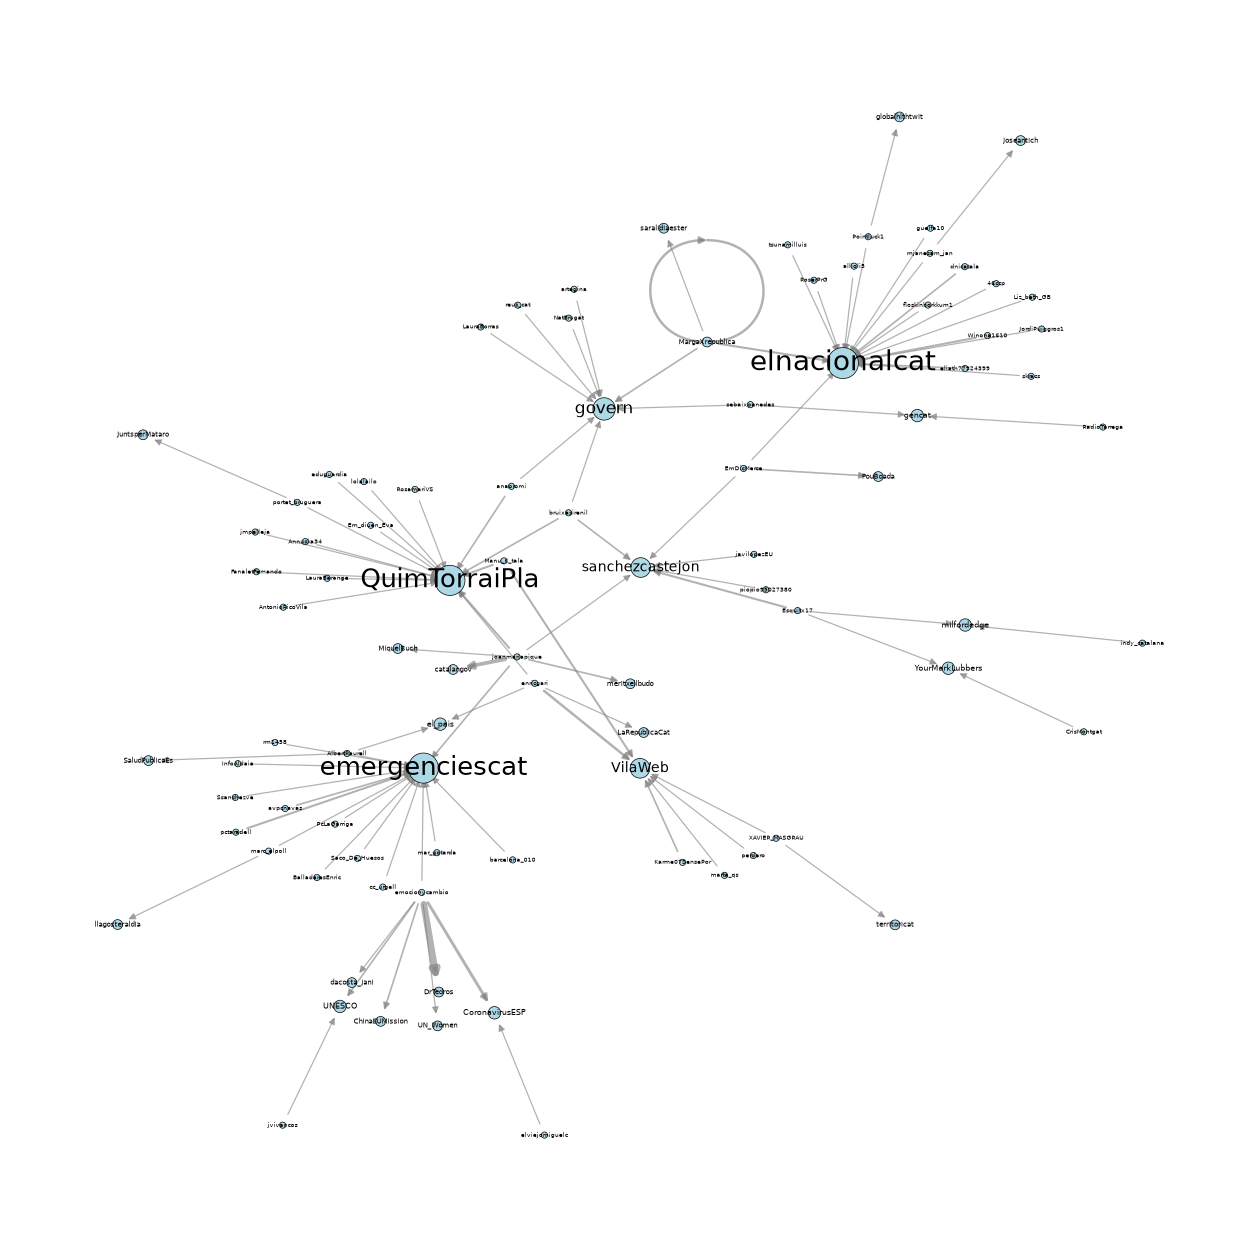

In [18]:
nodes = list(lcc.nodes())      # Llista de nodes (fixem un ordre)
edges = list(lcc.edges())      # Llista d'arestes (fixem un ordre)
degree = dict(lcc.in_degree()) # Diccionari {node: in-degree} = nombre de mencions REBUDES

weights = []
for u, v in edges:
    w = lcc[u][v]['weight']    # Pes d'aquesta aresta
    weights.append(w)          # El guardem a la llista

node_sizes = [20 + 30 * degree[n] for n in nodes]   # Mida proporcional a in-degree (+20 perquè es vegin tots)
edge_widths = [0.3 * w for w in weights]            # Gruix proporcional al pes de l'aresta

plt.figure(figsize=(16, 16))

nx.draw_networkx_nodes(lcc, pos, nodelist=nodes, node_size=node_sizes,
                       node_color='lightblue', edgecolors='black', linewidths=0.5)
# edgecolors/linewidths = contorn negre fi del node

nx.draw_networkx_edges(lcc, pos, edgelist=edges, width=edge_widths,
                       arrows=True, arrowstyle='-|>', arrowsize=10,
                       edge_color='gray', alpha=0.6)
# arrows=True: dibuixa fletxes (graf dirigit). arrowstyle='-|>' = fletxa amb cap ple

for n in nodes:
    nx.draw_networkx_labels(lcc, pos, labels={n: n}, font_size=4 + degree[n])
# Una etiqueta cada vegada perquè la mida de la lletra depèn de l'in-degree
# (labels={n: n} = només aquest node, amb el seu nom com a text)

plt.axis('off')
plt.savefig("mentions-largest-cc.png", dpi=300, bbox_inches='tight')
# Guarda la figura en PNG (dpi=300 = alta resolució; bbox_inches='tight' retalla els marges).
# IMPORTANT: savefig ha d'anar ABANS de plt.show(), si no es guarda en blanc
plt.show()

<font size="+1" color="red">

Replace this cell with a basic analysis of the network structure, using `networkx` functions (see [Algorithms](https://networkx.org/documentation/stable/reference/algorithms/index.html) and [Graph Functions](https://networkx.org/documentation/stable/reference/functions.html#graph)).

* What is the diameter of the largest connected component, disregarding edge direction?
* What is the size of the largest connected component, both as a number of nodes and as a percentage of the nodes in the graph?
* What is the size of the second largest connected component?

</font>


In [19]:
diameter = nx.diameter(lcc.to_undirected())
# Diàmetre = la distància més llarga entre dos nodes (en nombre de salts, camins més curts).
# Només es pot calcular en un graf connex, per això usem la LCC. to_undirected per ignorar fletxes
print(f"Diàmetre de la LCC és {diameter}")

nombre_lcc = lcc.number_of_nodes()
nombre_total = g.number_of_nodes()
print(f"LCC:{nombre_lcc} nodes,{100*nombre_lcc/nombre_total:.1f}% dels nodes totals")   # Percentatge amb 1 decimal

components = sorted(nx.weakly_connected_components(g), key=len, reverse=True)
# Totes les components ordenades de més gran a més petita
print(f"La segona component és de {len(components[1])} nodes")   # [1] = la segona
print(len(components))                                              # Nombre total de components

Diàmetre de la LCC és 10
LCC:90 nodes,25.2% dels nodes totals
La segona component és de 17 nodes
112


Interpretació (la teva, ordenada): la LCC conté un ~25% dels nodes: és gran però hi ha moltes components petites i poc connectades, és a dir, una xarxa fragmentada amb un nucli gran i molts grups petits a part. El diàmetre és relativament gran respecte a la mida de la LCC, la qual cosa indica una estructura allargada, no gaire densa. Sobre el dibuix: amb la mateixa xarxa pero un altre seed, el dibuix pot sortir girat o reflectit; el que importa és l'estructura (qui està connectat amb qui), no les coordenades absolutes.


## 2.3. Examine degree distributions


Analyze the in- and out-degree distributions of nodes in the **largest connected component**:

* Plot both distributions.
* Plot a **scatterplot** of the in and out degree of nodes.

*Important: Make sure the plots are readable! Include x- and y-axis labels, a legend, etc.*

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

<font size="+1" color="red">Replace this cell with code to show the in- and out-degree distributions of nodes.</font>


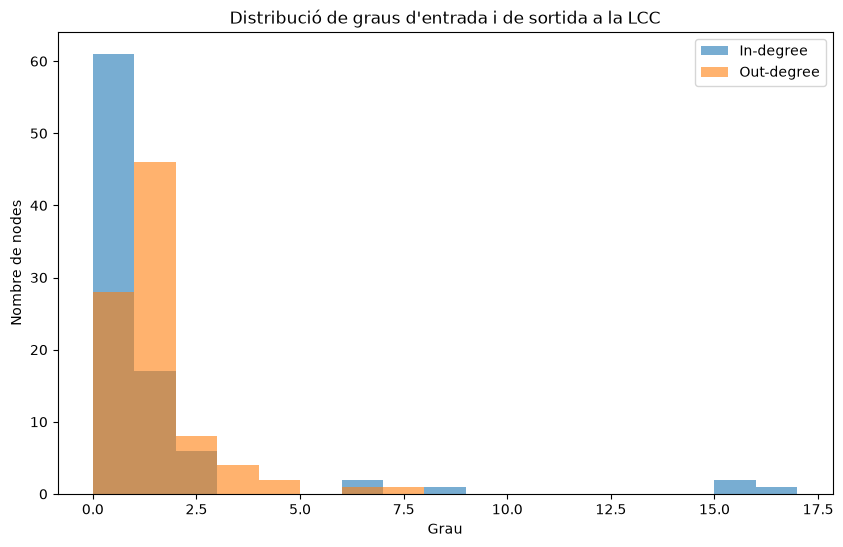

In [20]:
in_degrees = []
out_degrees = []
for n in lcc.nodes():
    in_degrees.append(lcc.in_degree(n))     # Mencions REBUDES (fletxes que arriben al node)
    out_degrees.append(lcc.out_degree(n))   # Mencions FETES (fletxes que surten del node)

plt.figure(figsize=(10, 6))

max_deg = max(max(in_degrees), max(out_degrees))   # El grau més alt de totes dues llistes
bins = range(0, max_deg + 2)                       # Una barra per cada valor enter de grau (+2 perquè el final no s'inclou)

plt.hist(in_degrees, bins=bins, alpha=0.6, label='In-degree')    # Histograma 1 (alpha = transparència perquè es vegin tots dos)
plt.hist(out_degrees, bins=bins, alpha=0.6, label='Out-degree')  # Histograma 2

plt.xlabel('Grau')
plt.ylabel('Nombre de nodes')
plt.title("Distribució de graus d'entrada i de sortida a la LCC")
plt.legend()      # Mostra la llegenda amb els 'label' dels histogrames
plt.show()

Interpretació: la majoria de nodes tenen graus baixos i uns pocs tenen graus molt alts (cua llarga). Hi ha comptes amb in-degree molt alt (molt mencionats: mitjans, institucions) i comptes amb out-degree alt (mencionen molt, però no els mencionen).


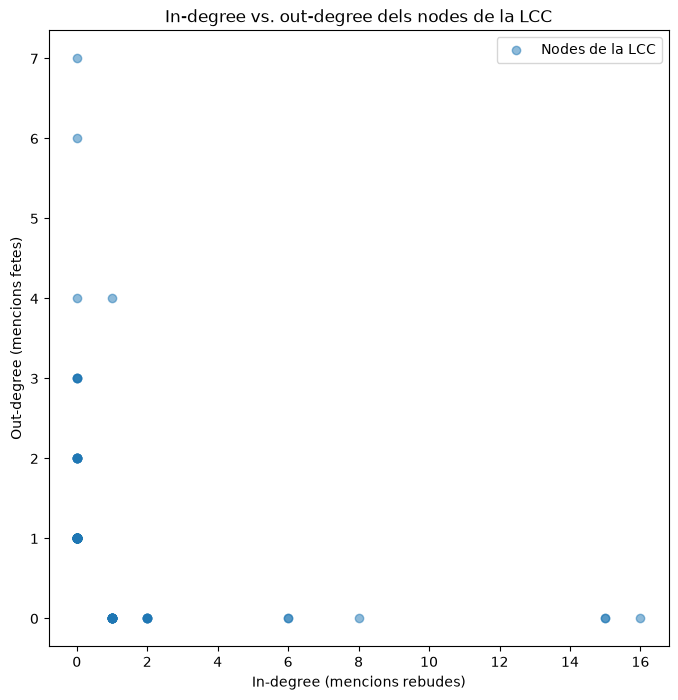

In [21]:
plt.figure(figsize=(8, 8))
plt.scatter(in_degrees, out_degrees, alpha=0.5, label='Nodes de la LCC')
# Diagrama de dispersió: cada punt és un node; X = in-degree, Y = out-degree
plt.xlabel("In-degree (mencions rebudes)")
plt.ylabel("Out-degree (mencions fetes)")
plt.title("In-degree vs. out-degree dels nodes de la LCC")
plt.legend()
plt.show()

<font size="+1" color="red">Replace this cell by a brief commentary, in your own words, about what you see on the scatterplot. What does it tell you about the largest strongly connected component of the graph?</font>


Interpretació: els punts són prop dels eixos: o un node rep molt i envia poc (hub receptor, p. ex. un mitjà), o envia molt i rep poc (compte actiu que menciona molts altres). Pocs nodes tenen els dos valors alts alhora.

# 3. Create the undirected co-mention network


The **undirected co-mention network** connects two accounts if they are both mentioned in the same tweet. The weight of the edge is the number of tweets in which the accounts are co-mentioned.

Suppose the mentions in a Tweet are in the array ``mentions``, one way to iterate through all pairs of co-mentioned is like this:

```python
    for mention1 in mentions:
        for mention2 in mentions:
            ...
```

Read the original input file again to create a dictionary `co_mentions_counter` in which keys are tuples (user1, user2) in which user1 lexicographically precedes user2 (user1 < user2), and values are the number of times user1 and user2 have appeared together in a tweet.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

<font size="+1" color="red">Replace this cell with your code to create the `co_mentions_counter`.</font>


In [22]:
co_mentions_counter = {}   # Clau = (usuari1, usuari2) amb usuari1 < usuari2; valor = nombre de tuits on coincideixen

with gzip.open(COMPRESSED_INPUT_FILENAME, "rt", encoding="utf-8") as input_file:
    for i in input_file:                                   # Un tuit per línia
        tweet = json.loads(i)
        mentions = set(extract_mentions(tweet['full_text']))
        # set() elimina repetits: si un tuit esmenta @a dues vegades, només compta una
        for i in mentions:           # Doble bucle per generar totes les parelles del tuit
            for j in mentions:
                if i < j:            # Només ordre alfabètic: cada parella surt 1 sola vegada i evitem (a,a)
                    clau = (i, j)
                    co_mentions_counter[clau] = co_mentions_counter.get(clau, 0) + 1

Print the number of times the accounts `educaciocat` and `elnacionalcat` have been mentioned together. It should be 8.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>


In [23]:
# Leave this code as-is

print(co_mentions_counter[('educaciocat', 'elnacionalcat')])

4


<font size="+1" color="red">Replace this cell with your code to print all pairs of accounts that have been co-mentioned 20 times or more.</font>


In [24]:
for (user1, user2) in co_mentions_counter:
    weight = co_mentions_counter[(user1, user2)]
    if weight >= 20:    # Filtre: parelles que coincideixen en 20 o més tuits
        print(f"Comptes @{user1} i @{user2} estan comencionades {weight} vegades")

Comptes @VilaWeb i @mossos estan comencionades 20 vegades
Comptes @QuimTorraiPla i @govern estan comencionades 91 vegades
Comptes @sanchezcastejon i @tjparfitt estan comencionades 28 vegades
Comptes @elnacionalcat i @joseantich estan comencionades 90 vegades
Comptes @QuimTorraiPla i @tjparfitt estan comencionades 59 vegades
Comptes @QuimTorraiPla i @sanchezcastejon estan comencionades 24 vegades
Comptes @emergenciescat i @govern estan comencionades 31 vegades
Comptes @josepcosta i @sanchezcastejon estan comencionades 49 vegades
Comptes @eldiarioes i @iescolar estan comencionades 28 vegades
Comptes @gencat i @govern estan comencionades 62 vegades
Comptes @mossos i @semgencat estan comencionades 44 vegades
Comptes @elnacionalcat i @juansrod1 estan comencionades 30 vegades
Comptes @QuimTorraiPla i @emergenciescat estan comencionades 75 vegades
Comptes @Antoni_Gelonch i @sanchezcastejon estan comencionades 106 vegades


Now create a file named `OUTPUT_CO_MENTIONS_FILENAME` containing co-mentions in tab-separated columns `Source, Target, Weight`.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

<font size="+1" color="red">Replace this cell with your code to create the co-mentions file.</font>

In [ ]:
lines_written = 0
with io.open(OUTPUT_CO_MENTIONS_FILENAME, "w") as output_file:
    writer = csv.writer(output_file, delimiter='\t', quotechar='"')
    writer.writerow(["Source", "Target", "Weight"])
    for (user1, user2), weight in co_mentions_counter.items():
        # .items() retorna (clau, valor); la clau és una tupla, i la desempaquetem directament
        writer.writerow([user1, user2, weight])
        lines_written += 1

print(f"Escrites {lines_written} files al file {OUTPUT_CO_MENTIONS_FILENAME}")

# 4. Visualize the undirected co-mention network 

Read the co-mentions file and create a `Graph` in which nodes are accounts and the links between them are weighted by the number of co-mentions.

Find the nodes that have a **degree larger or equal to 17**, and then create a `subgraph` with those nodes and the edges between them.

Visualize the network using a `spring_layout` that uses the `weight` edge property. A few notes:

* You can take inspiration from the layout provided when we visualized the directed mentions network earlier in this practice. But try different versions — play around with the layout properties like `k`, the number of `iterations`, or the `gravity` (if using the 'energy' method).
* Try using the 'force' method of `spring_layout`, or a completely different layout if you'd like: check the NetworkX [Drawing](https://networkx.org/documentation/stable/reference/drawing.html) documentation for options.
* Keep in mind this network is larger, so it may take more time to visualize it. Usually the most time-consuming part is calculating the layout coordinates `pos`. Some layouts are faster than others.

Style the network as you wish, what matters in the end is that your visualization is readable and the layout and styling is meaningful.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

Nodes: 4008, arestes: 7816
Subgraf: 138 nodes, 1823 arestes


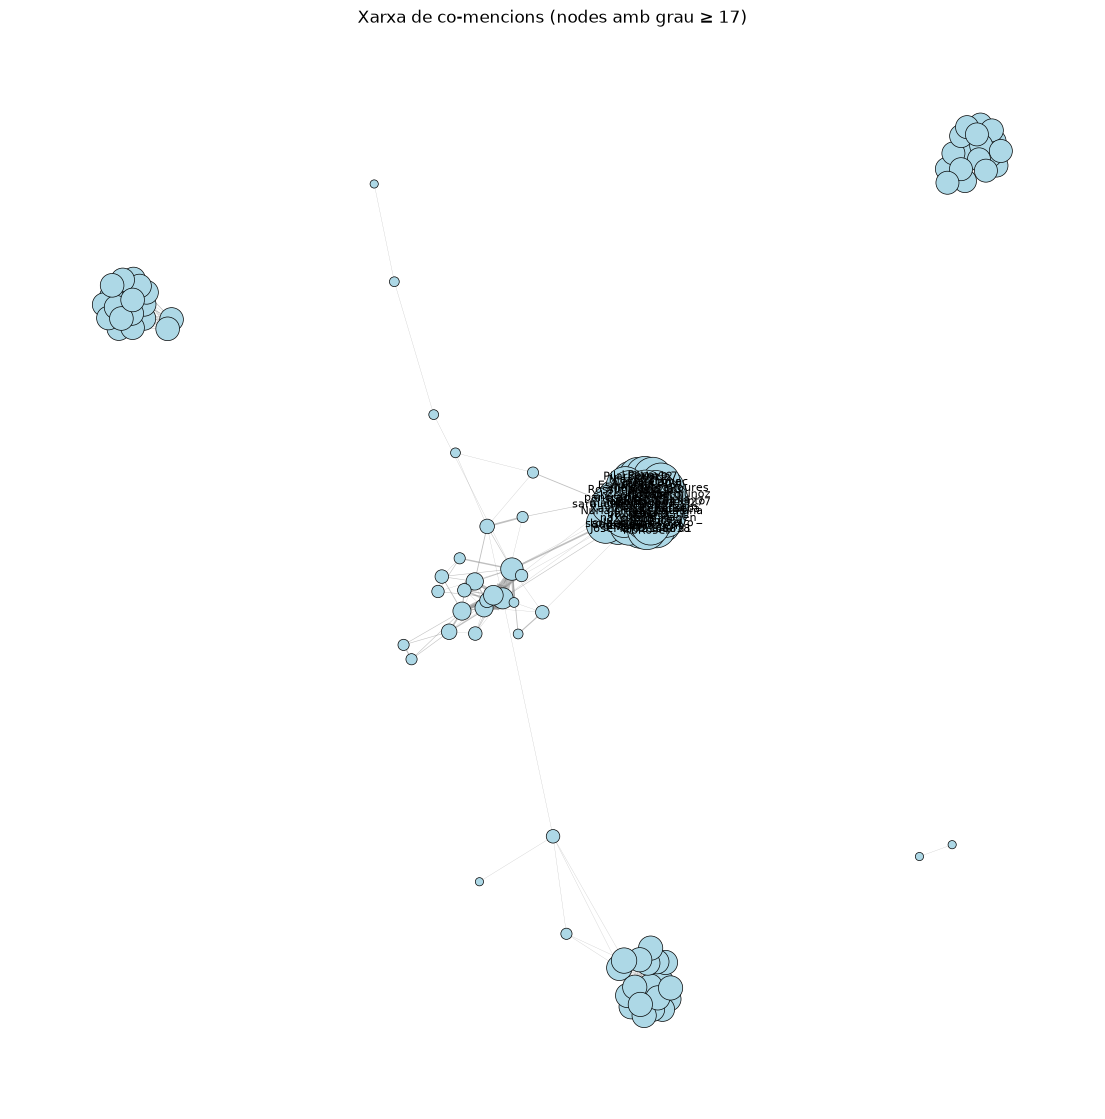

In [25]:
g_co = nx.Graph()    # Graf NO dirigit (les co-mencions no tenen sentit)

with open(OUTPUT_CO_MENTIONS_FILENAME, "r") as input_file:
    reader = csv.DictReader(input_file, delimiter='\t')
    for i in reader:
        g_co.add_edge(i['Source'], i['Target'], weight=int(i['Weight']))

print(f"Nodes: {g_co.number_of_nodes()}, arestes: {g_co.number_of_edges()}")

high_degree_nodes = []
for n in g_co.nodes():
    if g_co.degree(n) >= 17:        # Ens quedem només amb nodes de grau >= 17 (la xarxa completa és massa gran)
        high_degree_nodes.append(n)

sub = g_co.subgraph(high_degree_nodes).copy()   # Subgraf només amb aquests nodes
print(f"Subgraf: {sub.number_of_nodes()} nodes, {sub.number_of_edges()} arestes")

pos_co = nx.spring_layout(sub, weight='weight', k=0.3, iterations=100, seed=42)
# weight='weight': arestes amb més pes atrauen més. iterations=100: més passos = layout més estable

nodes = list(sub.nodes())
edges = list(sub.edges())

node_sizes = [20 + 15 * sub.degree(n) for n in nodes]                # Mida segons grau
edge_widths = [0.2 * sub[u][v]['weight'] for u, v in edges]          # Gruix segons pes

plt.figure(figsize=(14, 14))
nx.draw_networkx_edges(sub, pos_co, edgelist=edges, width=edge_widths, edge_color='gray', alpha=0.5)
nx.draw_networkx_nodes(sub, pos_co, nodelist=nodes, node_size=node_sizes,
                       node_color='lightblue', edgecolors='black', linewidths=0.5)

labels = {}                  # Diccionari {node: text} només per als nodes importants
for n in nodes:
    if sub.degree(n) >= 25:  # Etiquetem només els de grau >= 25 perquè el dibuix sigui llegible
        labels[n] = n
nx.draw_networkx_labels(sub, pos_co, labels=labels, font_size=8)

plt.axis('off')
plt.title("Xarxa de co-mencions (nodes amb grau ≥ 17)")
plt.savefig("co-mentions-network.png", dpi=300, bbox_inches='tight')
plt.show()

Interpretació (la teva, ordenada): hi ha una component gran amb nodes de grau alt que es retroalimenten entre ells (un nucli dens), i a part altres "estrelles" amb un hub central. Globalment la xarxa és poc densa, però localment, dins de cada component, la densitat és alta. Els noms de grau >= 25 revelen un hub molt rellevant.


# DELIVER (individually)

Deliver a zip file containing:

* Your code as a Python notebook (a `.ipynb` file).
   * Remove all unnecessary elements
   * Add comments when needed
* Any `.png` files you generated in the notebook

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

<font size="+2" color="#003300">I hereby declare that, except for the code provided by the course instructors, all of my code, text, and figures were produced by myself.</font>